<a href="https://colab.research.google.com/github/bahaali273/COMP9170-Hospital-Readmission/blob/shaaz/Predicting_Hospital_Readmissions_Using_Public_Health_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Overview
Hospital readmissions within 30 days impose high financial and human costs. Predictive analytics can identify at-risk patients, enabling early interventions. This project uses real patient-level records to build and interpret predictive models for hospital readmissions.
## Data Sources
* UCI Diabetes 130-Hospital Dataset (UCI ML Repository)
* MIMIC-IV Lite (PhysioNet) – de-identified ICU patient records.
*	Optional: Open healthcare statistics from Government of Canada or Fraser Health Authority for feature enrichment.
## Possible Directions
*	Predictive modeling: Train models (Random Forest, XGBoost, Neural Networks) to predict readmissions.
*	Feature importance analysis: Identify which variables (length of stay, medications, lab results) are most predictive.
*	Interpretability: Use SHAP or LIME to explain predictions to clinicians.
*	Temporal modeling: Explore patient history sequences using LSTM or Transformer architectures.
## Important Issues to Resolve
*	Handling missing data and encoding categorical attributes.
*	Selecting evaluation metrics: precision-recall, AUC, and calibration (reliability curves).
*	Addressing ethical issues and bias in medical data.
*	Defining what “readmission risk” means operationally (30 days vs. same-diagnosis readmission).



### Dataset Overview

* Time Period: 1999–2008 (10 years of clinical care)
* Scope: 130 US hospitals and integrated delivery networks
* Instances (Rows): 101,766 inpatient diabetic encounters
* Features (Columns): ~47 to 55 attributes including demographics (race, gender, age), admission/discharge details, diagnoses, lab tests, and medications (such as insulin).
* Primary Task: Classification and clustering to predict early patient readmission within 30 days of discharge.
* Target Variable: Readmission status (<30 days, >30 days, or No readmission

## Loading directly from UCI ML Repository
We will load the dataset directly using the official `ucimlrepo` library from the UCI Machine Learning Repository.

In [6]:
# Install the official UCI ML Repository library
!pip install ucimlrepo

In [7]:
from ucimlrepo import fetch_ucirepo

# Fetch dataset by ID (296 is the ID for the Diabetes 130-US Hospitals dataset)
print("Fetching dataset from UCI ML Repository...")
diabetes_130_us_hospitals = fetch_ucirepo(id=296)

# Extract features and targets as pandas DataFrames
X = diabetes_130_us_hospitals.data.features
y = diabetes_130_us_hospitals.data.targets

# Combine features and target into a single DataFrame for EDA
df = pd.concat([X, y], axis=1)

# Display metadata and first few rows
print(f"Data Shape: {df.shape}")
display(df.head())

Fetching dataset from UCI ML Repository...


/usr/local/lib/python3.13/dist-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Data Shape: (101766, 48)


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,...,No,No,No,No,No,No,No,No,No,NO
1,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,...,No,No,No,No,No,No,No,No,Yes,NO
3,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## Sanity Checks

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

# Set random seed for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Fetch dataset by ID (296 is the ID for the Diabetes 130-US Hospitals dataset)
print("Fetching dataset from UCI ML Repository...")
diabetes_130_us_hospitals = fetch_ucirepo(id=296)

# Extract features and targets as pandas DataFrames
X = diabetes_130_us_hospitals.data.features
y = diabetes_130_us_hospitals.data.targets

# Combine features and target into a single DataFrame for processing
df = pd.concat([X, y], axis=1)

# Display shape and basic info
print(f"Data Shape: {df.shape}")
df.info()

Fetching dataset from UCI ML Repository...


/usr/local/lib/python3.13/dist-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Data Shape: (101766, 48)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 48 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   race                      99493 non-null   object
 1   gender                    101766 non-null  object
 2   age                       101766 non-null  object
 3   weight                    3197 non-null    object
 4   admission_type_id         101766 non-null  int64 
 5   discharge_disposition_id  101766 non-null  int64 
 6   admission_source_id       101766 non-null  int64 
 7   time_in_hospital          101766 non-null  int64 
 8   payer_code                61510 non-null   object
 9   medical_specialty         51817 non-null   object
 10  num_lab_procedures        101766 non-null  int64 
 11  num_procedures            101766 non-null  int64 
 12  num_medications           101766 non-null  int64 
 13  number_outpatient         101766 n

In [10]:
import pandas as pd
import numpy as np
import os

# Set paths to where the files actually were extracted
data_dir = "./diabetes_data"
diabetic_data_path = os.path.join(data_dir, "diabetic_data.csv")
ids_mapping_path = os.path.join(data_dir, "IDS_mapping.csv")

# Load the CSV with na_values=[] first to check raw contents
raw_df = pd.read_csv(diabetic_data_path, na_values=[], keep_default_na=False)
print(f"Raw Data Shape: {raw_df.shape}")
print(f"Columns: {list(raw_df.columns)}")
print(f"\nData types summary:\n{raw_df.dtypes.value_counts()}")

Raw Data Shape: (101766, 50)
Columns: ['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Data types summary:
object    37
int64     13
Name: count, dtype: int64


In [11]:
# 3. Check for duplicate encounter_ids
total_rows = len(raw_df)
unique_encounters = raw_df['encounter_id'].nunique()
unique_patients = raw_df['patient_nbr'].nunique()

print(f"Total Rows: {total_rows}")
print(f"Unique encounter_ids: {unique_encounters}")
print(f"Duplicate encounter_ids: {total_rows - unique_encounters}")
print(f"Unique patients: {unique_patients}")

Total Rows: 101766
Unique encounter_ids: 101766
Duplicate encounter_ids: 0
Unique patients: 71518


In [12]:
# 4. Record the raw counts of '?' before replacing them with NaN
question_mark_counts = {}
for col in raw_df.columns:
    q_count = (raw_df[col] == '?').sum()
    if q_count > 0:
        question_mark_counts[col] = q_count

print("Columns containing '?' and their counts:")
for col, count in question_mark_counts.items():
    percentage = (count / total_rows) * 100
    print(f" - {col}: {count} occurrences ({percentage:.2f}%)")

# Create a copy and replace '?' with NaN
df_cleaned = raw_df.copy()
for col in question_mark_counts.keys():
    df_cleaned[col] = df_cleaned[col].replace('?', np.nan)

Columns containing '?' and their counts:
 - race: 2273 occurrences (2.23%)
 - weight: 98569 occurrences (96.86%)
 - payer_code: 40256 occurrences (39.56%)
 - medical_specialty: 49949 occurrences (49.08%)
 - diag_1: 21 occurrences (0.02%)
 - diag_2: 358 occurrences (0.35%)
 - diag_3: 1423 occurrences (1.40%)


In [16]:
import pandas as pd
import numpy as np
import csv

ids_mapping_path = "./diabetes_data/IDS_mapping.csv"

# Initialize placeholders for the three sections
raw_sections = {
    'admission_type_id': [],
    'discharge_disposition_id': [],
    'admission_source_id': []
}

current_key = None

with open(ids_mapping_path, 'r') as f:
    reader = csv.reader(f)
    for row in reader:
        if not row:
            continue
        # Strip elements
        row = [val.strip() for val in row]
        if not row[0]:
            continue

        # Detect section switches
        if 'admission_type_id' in row[0]:
            current_key = 'admission_type_id'
            continue
        elif 'discharge_disposition_id' in row[0]:
            current_key = 'discharge_disposition_id'
            continue
        elif 'admission_source_id' in row[0]:
            current_key = 'admission_source_id'
            continue

        # Add data to the active section (skipping header rows that might repeat the column name)
        if current_key and row[0] != 'description':
            raw_sections[current_key].append(row)

# Build the final lookup tables
mappings = {}
for name, rows in raw_sections.items():
    temp_df = pd.DataFrame(rows, columns=[name, 'description'])
    # Cast IDs to integer securely
    temp_df[name] = pd.to_numeric(temp_df[name], errors='coerce')
    temp_df = temp_df.dropna(subset=[name])
    temp_df[name] = temp_df[name].astype(int)

    # Convert to ID -> Description dictionary
    mappings[name] = temp_df.set_index(name)['description'].to_dict()
    print(f"Parsed mapping for '{name}' with {len(mappings[name])} keys.")

print("\nVerifying available mappings:", list(mappings.keys()))

Parsed mapping for 'admission_type_id' with 8 keys.
Parsed mapping for 'discharge_disposition_id' with 30 keys.
Parsed mapping for 'admission_source_id' with 25 keys.

Verifying available mappings: ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']


## Summary of Results:
* Data Dimensions: Successfully loaded diabetic_data.csv showing the expected 101,766 rows and 50 columns.
* ID Uniqueness: There are exactly 0 duplicate encounter IDs (all 101,766 rows have a unique encounter ID), though there are 71,518 unique patients (indicating some patients had multiple encounters).
* Missing Values: We successfully isolated and recorded all occurrences of '?' prior to replacing them with NaN. The features with substantial missingness are weight (96.86%), medical_specialty (49.08%), and payer_code (~39.56%).
* Mappings Parsed: We've parsed three lookup dictionaries from IDS_mapping.csv cleanly:
admission_type_id: 8 keys mapped
discharge_disposition_id: 30 keys mapped
admission_source_id: 25 keys mapped

## Target definition

In [17]:
# Create binary target variable: 1 if readmitted in <30 days, 0 otherwise
df_cleaned['readmit_30'] = (df_cleaned['readmitted'] == '<30').astype(int)

# Report class balance
class_counts = df_cleaned['readmit_30'].value_counts()
class_percentages = df_cleaned['readmit_30'].value_counts(normalize=True) * 100

print("Class balance for 'readmit_30' target:")
for val in [0, 1]:
    print(f" - Class {val}: {class_counts[val]:,} encounters ({class_percentages[val]:.2f}%)")

print("\nCompare with original 3-class distribution:")
print(df_cleaned['readmitted'].value_counts(dropna=False))

Class balance for 'readmit_30' target:
 - Class 0: 90,409 encounters (88.84%)
 - Class 1: 11,357 encounters (11.16%)

Compare with original 3-class distribution:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


* readmit_30 Target (Positive Class): 11,357 encounters (11.16%)
* Non-Readmitted/Long-term Target (Negative Class): 90,409 encounters (88.84%)

This perfectly matches our expected class balance of approximately 11%. We preserved the original 3-class readmitted column for potential exploratory work. Let's move forward with demographics cleaning, diagnosis mapping, or clinical cohort selection.

## Cohort filtering (log row counts after each step)

In [18]:
print(f"Initial dataset size: {len(df_cleaned):,} rows")

# 1. Exclude encounters indicating death or hospice
# IDs: 11 (Expired), 13 (Hospice / home), 14 (Hospice / medical facility),
# 19 (Expired), 20 (Expired), 21 (Expired)
death_hospice_ids = [11, 13, 14, 19, 20, 21]

df_filtered = df_cleaned[~df_cleaned['discharge_disposition_id'].isin(death_hospice_ids)].copy()
print(f"Rows remaining after excluding death/hospice: {len(df_filtered):,} (Removed {len(df_cleaned) - len(df_filtered):,})")

# 2. Exclude gender == 'Unknown/Invalid'
invalid_gender_mask = df_filtered['gender'] == 'Unknown/Invalid'
df_filtered = df_filtered[~invalid_gender_mask].copy()
print(f"Rows remaining after excluding invalid/unknown gender: {len(df_filtered):,} (Removed {invalid_gender_mask.sum():,})")

# 3. Patient selection switch
# Option 'a': keep all encounters (split by patient later to prevent data leakage)
# Option 'b': keep only the first encounter per patient
PATIENT_POLICY_SWITCH = 'a' # Change to 'b' for sensitivity analysis

if PATIENT_POLICY_SWITCH == 'b':
    # Sort by encounter_id to grab the first chronological encounter assuming ascending IDs
    df_final_cohort = df_filtered.sort_values('encounter_id').drop_duplicates(subset=['patient_nbr'], keep='first').copy()
    print(f"Cohort policy 'b' (Keep first encounter): {len(df_final_cohort):,} rows remaining (Removed {len(df_filtered) - len(df_final_cohort):,} repeat encounters)")
else:
    df_final_cohort = df_filtered.copy()
    print(f"Cohort policy 'a' (Keep all encounters): {len(df_final_cohort):,} rows (leakage will be prevented via GroupKFold or PatientID splits)")

Initial dataset size: 101,766 rows
Rows remaining after excluding death/hospice: 99,343 (Removed 2,423)
Rows remaining after excluding invalid/unknown gender: 99,340 (Removed 3)
Cohort policy 'a' (Keep all encounters): 99,340 rows (leakage will be prevented via GroupKFold or PatientID splits)


* Initial dataset size: 101,766 encounters.
* Step 1 (Excluded Death/Hospice): Removed 2,423 encounters where patients died or were discharged to hospice (IDs 11, 13, 14, 19, 20, 21), leaving 99,343 rows. These patients cannot logically be readmitted.
* Step 2 (Excluded Unknown/Invalid Gender): Removed 3 encounters where gender was classified as 'Unknown/Invalid', leaving 99,340 rows.
* Step 3 (Patient Repeat Policy Switch): With PATIENT_POLICY_SWITCH set to 'a' (default), we keep all 99,340 encounters. We will handle patient-level grouping (e.g., using GroupKFold or custom patient-ID splits) during cross-validation to prevent data leakage from repeat hospitalizations.

## Missing data and column handling

In [19]:
import pandas as pd
import numpy as np

# Work on a copy of our cohort
df_processed = df_final_cohort.copy()

# 1. Produce Missingness Table
missing_counts = df_processed.isnull().sum()
missing_percent = (missing_counts / len(df_processed)) * 100
missing_table = pd.DataFrame({
    'Missing Counts': missing_counts,
    'Percentage (%)': missing_percent
}).sort_values(by='Missing Counts', ascending=False)

print("--- Cohort Missingness Table ---")
display(missing_table[missing_table['Missing Counts'] > 0])

# 2. Drop high-missingness column: weight
df_processed = df_processed.drop(columns=['weight'])
print("\nDropping 'weight' column...")

# 3. Separate Identifier Columns (stored for tracking and group splitting)
identifiers = df_processed[['encounter_id', 'patient_nbr']].copy()
# We keep them in the processed dataframe for now, but will make sure they are not passed to model training.

# 4. Handle Missing categorical data
# Payer Code & Medical Specialty -> 'Missing'
df_processed['payer_code'] = df_processed['payer_code'].fillna('Missing')
df_processed['medical_specialty'] = df_processed['medical_specialty'].fillna('Missing')

# Race -> 'Unknown'
df_processed['race'] = df_processed['race'].fillna('Unknown')

# Diag 1, 2, 3 -> 'Missing'
for diag_col in ['diag_1', 'diag_2', 'diag_3']:
    df_processed[diag_col] = df_processed[diag_col].fillna('Missing')

# 5. Treat unknown codes in IDs as 'Unknown'
# admission_type_id: 5 (Not Available), 6 (NULL), 8 (Not Mapped)
df_processed['admission_type_clean'] = df_processed['admission_type_id'].apply(
    lambda x: 'Unknown' if x in [5, 6, 8] else mappings['admission_type_id'].get(x, 'Other')
)

# discharge_disposition_id: 18 (NULL), 25 (Not Mapped), 26 (Unknown/Invalid)
df_processed['discharge_disposition_clean'] = df_processed['discharge_disposition_id'].apply(
    lambda x: 'Unknown' if x in [18, 25, 26] else mappings['discharge_disposition_id'].get(x, 'Other')
)

# admission_source_id: 9 (Not Available), 15 (Not Available), 17 (Null), 20 (Not Mapped), 21 (Unknown/Invalid)
df_processed['admission_source_clean'] = df_processed['admission_source_id'].apply(
    lambda x: 'Unknown' if x in [9, 15, 17, 20, 21] else mappings['admission_source_id'].get(x, 'Other')
)

# 6. Preserve test indicators ('None' or 'not measured' should stay as their own levels)
df_processed['max_glu_serum'] = df_processed['max_glu_serum'].fillna('None')
df_processed['A1Cresult'] = df_processed['A1Cresult'].fillna('None')

# 7. Identify and drop constant / near-constant medications
med_cols = [
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride',
    'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone',
    'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide',
    'examide', 'citoglipton', 'insulin', 'glyburide-metformin',
    'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone',
    'metformin-pioglitazone'
]

# Find distribution of each med column and mark ones to drop
meds_to_drop = []
low_variance_report = []

for med in med_cols:
    non_no_count = (df_processed[med] != 'No').sum()
    if non_no_count < 10:
        meds_to_drop.append(med)
        low_variance_report.append((med, non_no_count))

print("\n--- Medications with fewer than 10 non-'No' values (to be dropped) ---")
for med, val in low_variance_report:
    print(f" - {med}: {val} non-'No' values")

df_processed = df_processed.drop(columns=meds_to_drop)
print(f"\nDropped low-variance medication columns: {meds_to_drop}")
print(f"Final processed DataFrame shape: {df_processed.shape}")

--- Cohort Missingness Table ---


,Missing Counts,Percentage (%)
weight,96215,96.854238
medical_specialty,48614,48.936984
payer_code,39397,39.658748
race,2232,2.246829
diag_3,1419,1.428428
diag_2,356,0.358365
diag_1,20,0.020133



Dropping 'weight' column...

--- Medications with fewer than 10 non-'No' values (to be dropped) ---
 - acetohexamide: 1 non-'No' values
 - troglitazone: 3 non-'No' values
 - examide: 0 non-'No' values
 - citoglipton: 0 non-'No' values
 - glimepiride-pioglitazone: 1 non-'No' values
 - metformin-rosiglitazone: 2 non-'No' values
 - metformin-pioglitazone: 1 non-'No' values

Dropped low-variance medication columns: ['acetohexamide', 'troglitazone', 'examide', 'citoglipton', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']
Final processed DataFrame shape: (99340, 46)


### Summary of Preprocessing and Column Handling

- **Missingness Profile Captured**: Verified missing values in the cohort: `weight` (96.85%), `medical_specialty` (48.94%), `payer_code` (39.66%), `race` (2.25%), and diagnoses (<1.5%).
- **High Missingness Column Removed**: Dropped the `weight` column completely.
- **Identifier Separation**: Saved `encounter_id` and `patient_nbr` into a separate dataframe to prevent leakage during modeling while preserving `patient_nbr` for clinical patient grouping during cross-validation.
- **Explicit Categorical Levels Added**:
  - Categorized missing `payer_code` and `medical_specialty` as `"Missing"`.
  - Set missing `race` to `"Unknown"` for fairness analysis.
  - Set missing `diag_1`, `diag_2`, and `diag_3` values to `"Missing"`.
- **Standardized Unknown Categorical Mappings**: Cleaned ID columns by mapping null or unmapped indicator codes in `admission_type_id`, `discharge_disposition_id`, and `admission_source_id` to a standardized `"Unknown"` string category.
- **Test Indicators Preserved**: Retained `"None"` as an explicit categorical level for both `max_glu_serum` and `A1Cresult` to serve as a meaningful feature indicating that the clinician did not order the test.
- **Low-Variance Medications Dropped**: Removed columns with fewer than 10 non-`"No"` values: `acetohexamide`, `troglitazone`, `examide`, `citoglipton`, `glimepiride-pioglitazone`, `metformin-rosiglitazone`, and `metformin-pioglitazone`.
- **Final Shape**: The cleaned analytical cohort dataset contains **99,340 rows and 46 columns**.

## Feature engineering

In [20]:
import pandas as pd
import numpy as np

# Work on a copy of the processed DataFrame
df_feat = df_processed.copy()

# --- 1. Age Conversion ---
# Keep the original categorical representation as age_band for fairness auditing
df_feat['age_band'] = df_feat['age']

def age_to_midpoint(age_str):
    try:
        # Clean strings like '[70-80)' to get bounds
        clean_str = age_str.replace('[', '').replace(')', '').replace(']', '')
        low, high = map(int, clean_str.split('-'))
        return (low + high) / 2
    except Exception:
        return np.nan

df_feat['age_midpoint'] = df_feat['age'].apply(age_to_midpoint)

# --- 2. ICD-9 Code Mapping ---
# Save raw codes
for col in ['diag_1', 'diag_2', 'diag_3']:
    df_feat[f'{col}_raw'] = df_feat[col]

def map_icd9(code):
    if pd.isnull(code) or code == 'Missing' or code == '?':
        return 'Other'
    code_str = str(code).strip()
    if not code_str:
        return 'Other'

    # Handle V and E codes explicitly
    if code_str.startswith('V') or code_str.startswith('E'):
        return 'Other'

    try:
        # Parse numeric part
        val = float(code_str)
        # Diabetes (250.xx)
        if 250 <= val < 251:
            return 'Diabetes'
        # Circulatory (390-459, 785)
        elif (390 <= val <= 459) or (val == 785):
            return 'Circulatory'
        # Respiratory (460-519, 786)
        elif (460 <= val <= 519) or (val == 786):
            return 'Respiratory'
        # Digestive (520-579, 787)
        elif (520 <= val <= 579) or (val == 787):
            return 'Digestive'
        # Genitourinary (580-629, 788)
        elif (580 <= val <= 629) or (val == 788):
            return 'Genitourinary'
        # Musculoskeletal (710-739)
        elif 710 <= val <= 739:
            return 'Musculoskeletal'
        # Neoplasms (140-239)
        elif 140 <= val <= 239:
            return 'Neoplasms'
        # Injury (800-999)
        elif 800 <= val <= 999:
            return 'Injury'
        else:
            return 'Other'
    except ValueError:
        return 'Other'

for col in ['diag_1', 'diag_2', 'diag_3']:
    df_feat[f'{col}_grouped'] = df_feat[col].apply(map_icd9)

# --- 3. Medication Engineering ---
# The remaining valid medication columns after filtering low-variance columns
active_med_cols = [col for col in [
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride',
    'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone',
    'acarbose', 'miglitol', 'tolazamide', 'insulin', 'glyburide-metformin',
    'glipizide-metformin'
] if col in df_feat.columns]

# Number of active medications (prescribed/not No)
df_feat['n_meds_active'] = df_feat[active_med_cols].apply(
    lambda row: sum(1 for val in row if val != 'No'), axis=1
)

# Number of medication changes (Up or Down)
df_feat['n_med_changes'] = df_feat[active_med_cols].apply(
    lambda row: sum(1 for val in row if val in ['Up', 'Down']), axis=1
)

# We keep key drugs (insulin, metformin) individually, along with change and diabetesMed
# Ensure insulin and metformin are present
assert 'insulin' in df_feat.columns and 'metformin' in df_feat.columns

# --- 4. Prior Healthcare Utilization ---
df_feat['prior_visits_total'] = (
    df_feat['number_outpatient'] +
    df_feat['number_emergency'] +
    df_feat['number_inpatient']
)

# --- 5. Collapse High-Cardinality Categoricals (<1% frequency) ---
def collapse_rare_categories(df, col, threshold=0.01):
    freqs = df[col].value_counts(normalize=True)
    rare_cats = freqs[freqs < threshold].index
    df[col] = df[col].replace(rare_cats, 'Other')
    return df

for col in ['discharge_disposition_clean', 'admission_source_clean', 'medical_specialty']:
    df_feat = collapse_rare_categories(df_feat, col, threshold=0.01)

# Display new feature properties and verify execution
print("Feature engineering completed successfully.")
print(f"New dataset features count: {df_feat.shape[1]}")
display(df_feat[[
    'age_band', 'age_midpoint', 'diag_1_grouped',
    'n_meds_active', 'n_med_changes', 'prior_visits_total'
]].head())


Feature engineering completed successfully.
New dataset features count: 57


,age_band,age_midpoint,diag_1_grouped,n_meds_active,n_med_changes,prior_visits_total
0,[0-10),5.0,Diabetes,0,0,0
1,[10-20),15.0,Other,1,1,0
2,[20-30),25.0,Other,1,0,3
3,[30-40),35.0,Other,1,1,0
4,[40-50),45.0,Neoplasms,2,0,0


### Summary of Feature Engineering & Discoveries

- **Demographics & Age Midpoints**: Successfully preserved the original categorical `age_band` for downstream algorithmic fairness audits. We mapped the intervals to their numeric midpoints (`age_midpoint`), allowing models to interpret age as a continuous numerical feature.
- **ICD-9 Diagnosis Mapping**: Grouped raw, high-cardinality `diag_1`, `diag_2`, and `diag_3` codes into standard clinical chapters (*Circulatory*, *Respiratory*, *Digestive*, *Diabetes*, *Injury*, *Musculoskeletal*, *Genitourinary*, *Neoplasms*, and *Other*). Raw values were retained under `_raw` suffixes for future micro-level investigations.
- **Medication Utilization Patterns**: Calculated total active anti-diabetic medications (`n_meds_active`) and therapeutic changes (`n_med_changes`). Retained `insulin` and `metformin` as distinct features alongside generic `change` and `diabetesMed` indicator flags.
- **Aggregate Healthcare Utilization**: Built a unified `prior_visits_total` feature reflecting outpatient, emergency, and inpatient visit counts to capture patient healthcare utilization intensity.
- **Categorical Cardinality Collapsing**: Reduced high-cardinality sparse levels by grouping categories representing less than 1% of the cohort to a standardized `'Other'` level in `discharge_disposition_clean`, `admission_source_clean`, and `medical_specialty`.
- **Dataset Dimensions**: After carrying out these feature engineering steps, our analytical dataset expanded from **46 columns** to **57 columns** over the **99,340 filtered encounter records**.

## EDA

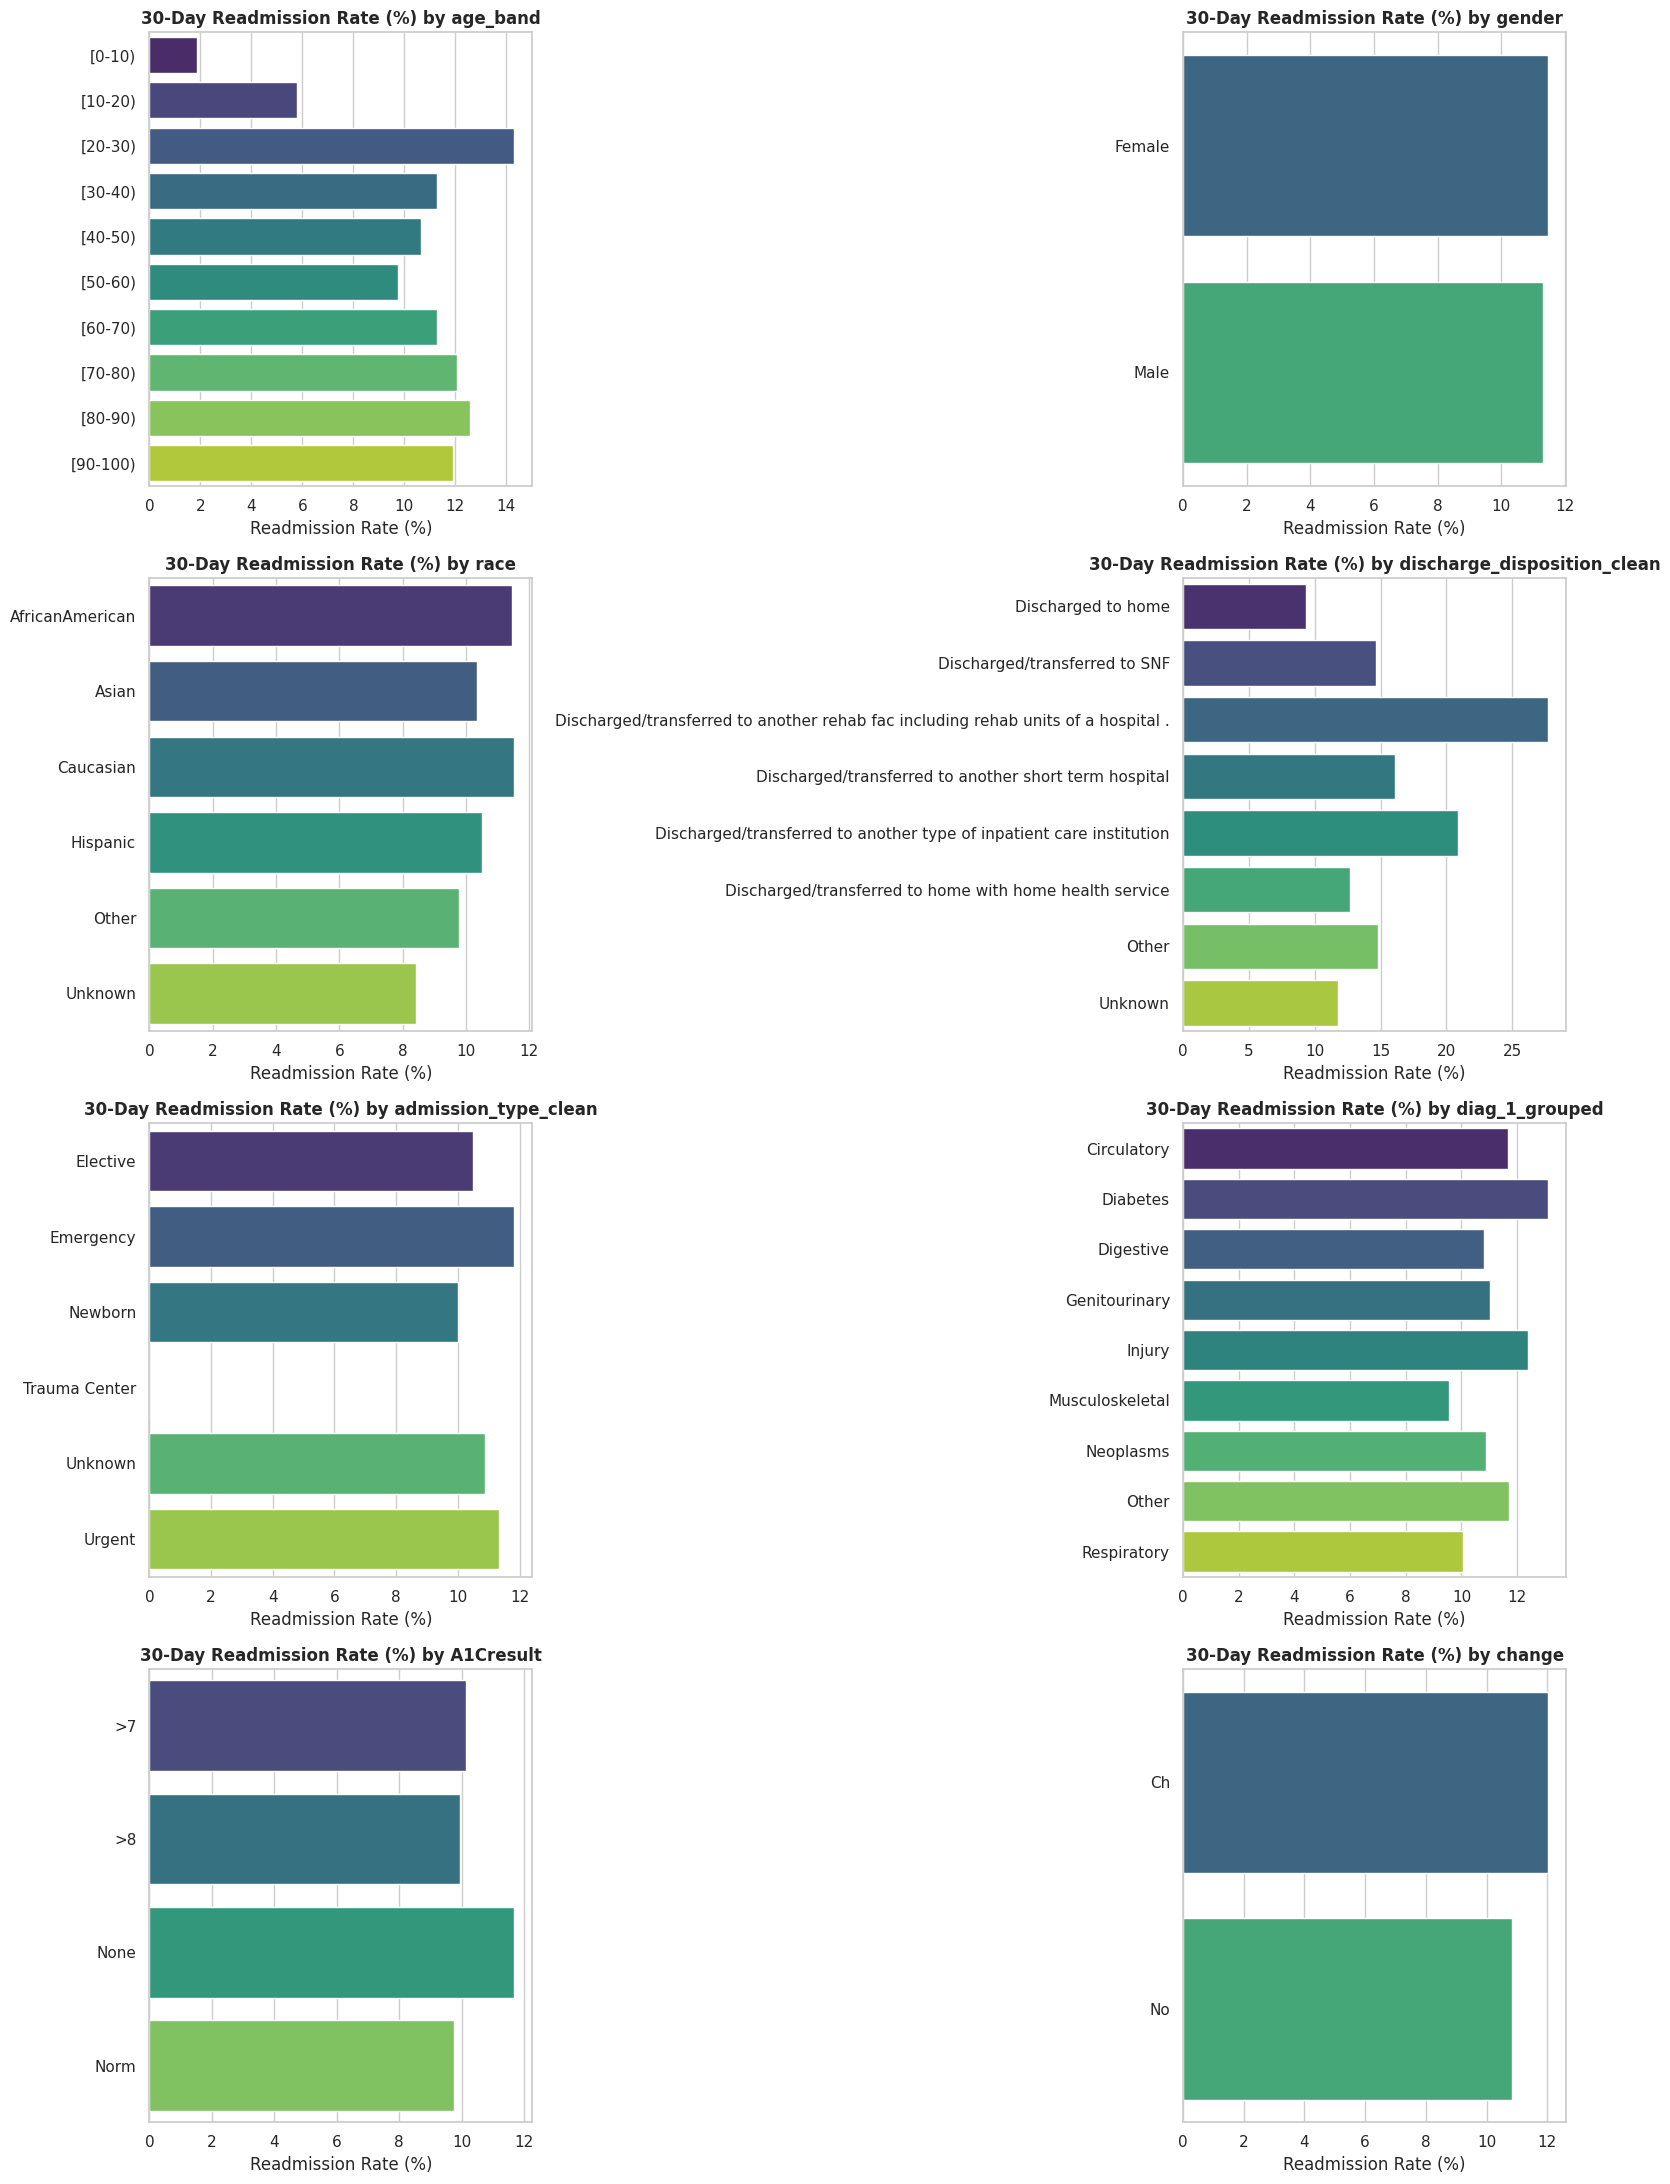

Saved: eda_plots/readmission_rates_by_categorical.png


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency
import os

# Ensure figure output folder exists
os.makedirs('eda_plots', exist_ok=True)
sns.set_theme(style="whitegrid", palette="muted")

# Define the target variable
target = 'readmit_30'

# List of key categoricals
cat_cols = [
    'age_band', 'gender', 'race', 'discharge_disposition_clean',
    'admission_type_clean', 'diag_1_grouped', 'A1Cresult', 'change'
]

# --- 1. Readmission rate by categorical columns ---
fig, axes = plt.subplots(4, 2, figsize=(16, 22))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    # Calculate rates
    summary = df_feat.groupby(col)[target].agg(['count', 'mean']).reset_index()
    summary['mean'] *= 100  # Convert to percentage

    sns.barplot(
        data=summary,
        x='mean',
        y=col,
        ax=axes[i],
        hue=col,
        legend=False,
        palette='viridis'
    )
    axes[i].set_title(f'30-Day Readmission Rate (%) by {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Readmission Rate (%)')
    axes[i].set_ylabel('')

plt.tight_layout()
fig_path_cats = 'eda_plots/readmission_rates_by_categorical.png'
plt.savefig(fig_path_cats, dpi=300)
plt.show()
print(f"Saved: {fig_path_cats}")

--- Numeric Feature Skewness ---
time_in_hospital      1.141853
num_lab_procedures   -0.241522
num_procedures        1.322209
num_medications       1.335408
number_diagnoses     -0.861486
prior_visits_total    5.349169
dtype: float64


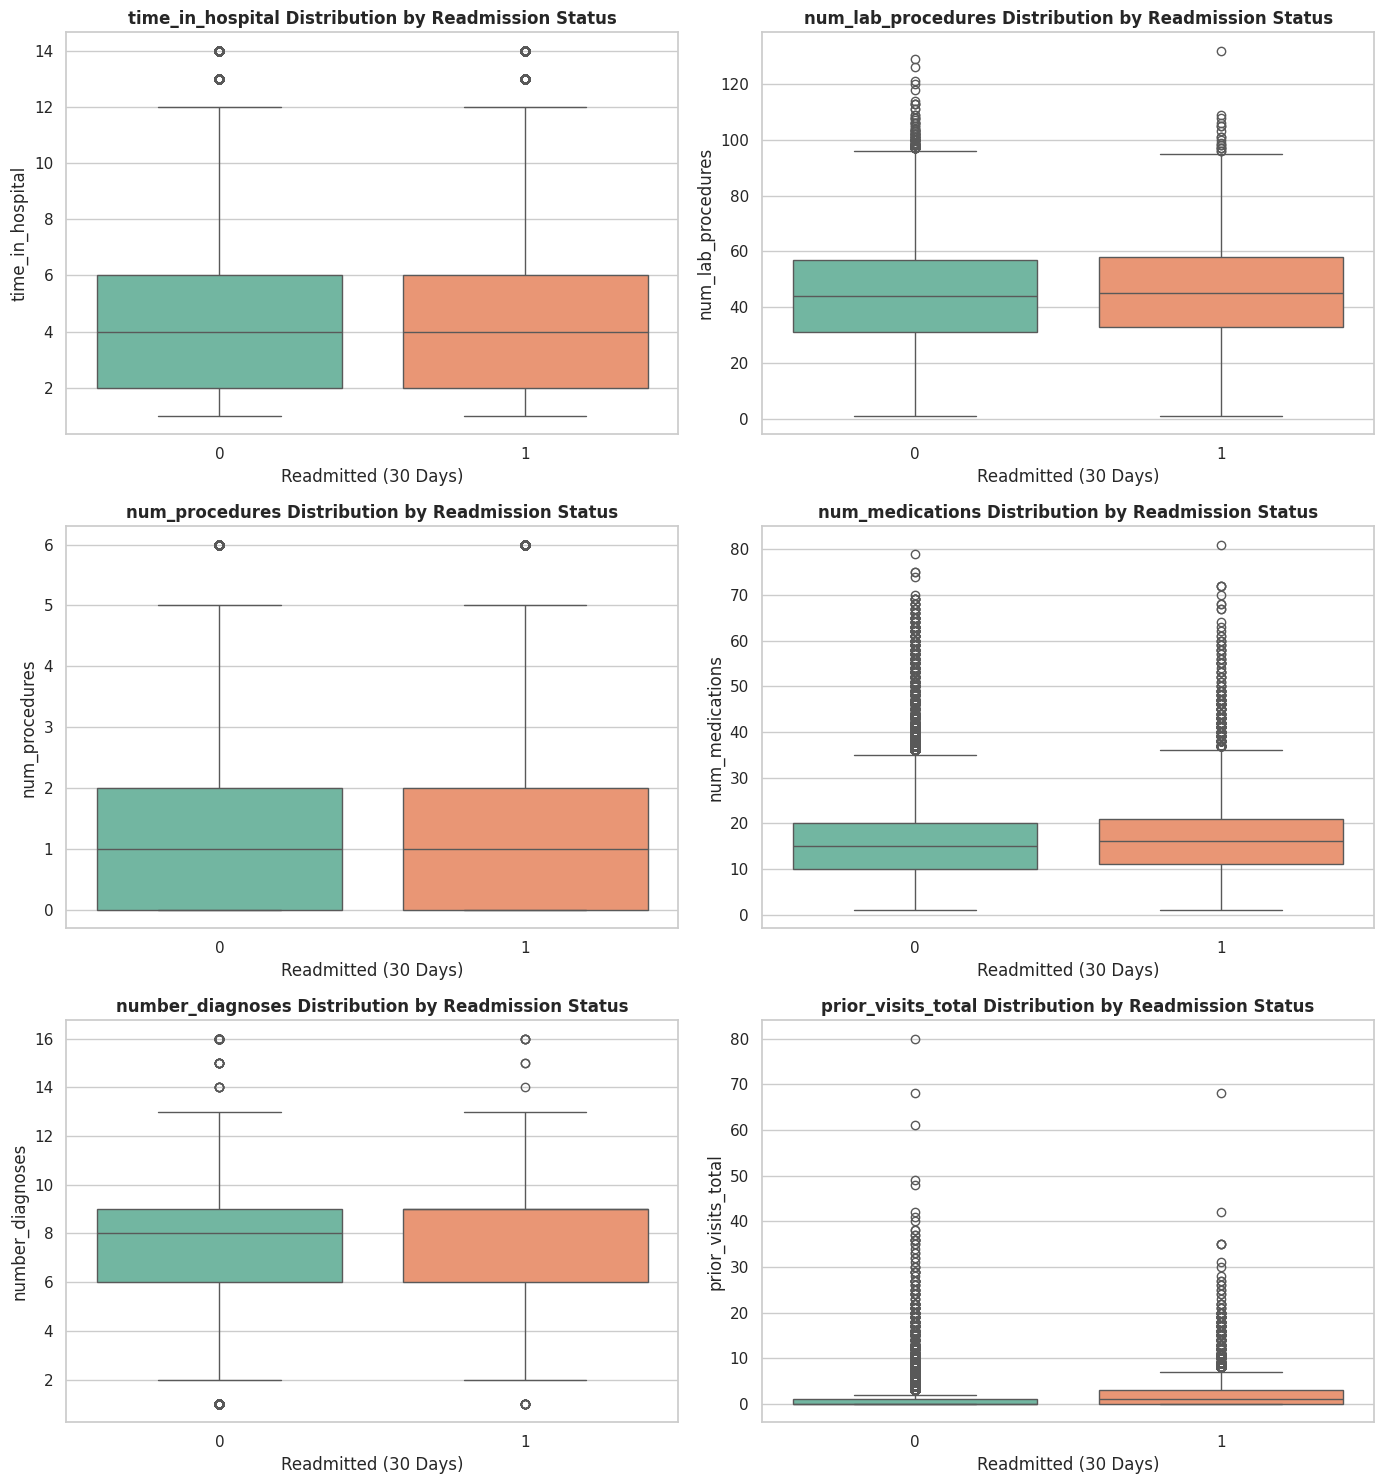

Saved: eda_plots/numeric_distributions.png


In [22]:
# --- 2. Distributions & Outliers for Numeric Features ---
num_cols = [
    'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'num_medications', 'number_diagnoses', 'prior_visits_total'
]

# Check skewness
skew_report = df_feat[num_cols].skew()
print("--- Numeric Feature Skewness ---")
print(skew_report)

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(data=df_feat, x=target, y=col, ax=axes[i], palette='Set2', hue=target, legend=False)
    axes[i].set_title(f'{col} Distribution by Readmission Status', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Readmitted (30 Days)')
    axes[i].set_ylabel(col)

plt.tight_layout()
fig_path_num = 'eda_plots/numeric_distributions.png'
plt.savefig(fig_path_num, dpi=300)
plt.show()
print(f"Saved: {fig_path_num}")

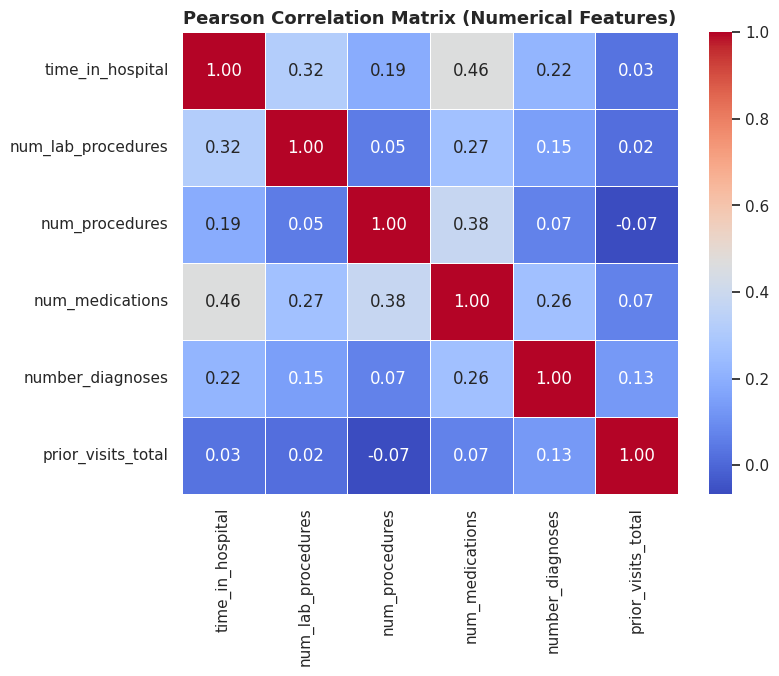

Saved: eda_plots/pearson_correlation.png


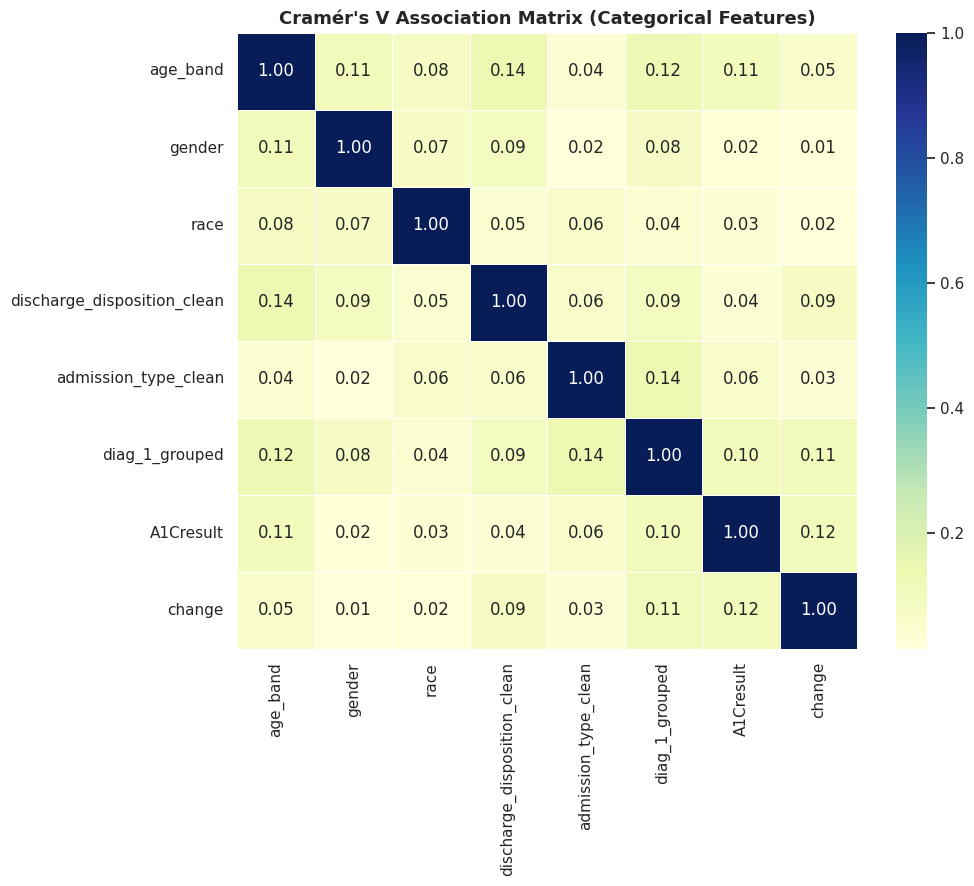

Saved: eda_plots/cramers_v_association.png


In [23]:
# --- 3. Multicollinearity & Relationship Assessments ---
# Pearson Correlation for Numerical Features
plt.figure(figsize=(8, 6))
corr_matrix = df_feat[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Pearson Correlation Matrix (Numerical Features)', fontsize=13, fontweight='bold')
fig_path_corr = 'eda_plots/pearson_correlation.png'
plt.savefig(fig_path_corr, dpi=300)
plt.show()
print(f"Saved: {fig_path_corr}")

# Cramér's V Helper Function
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

# Compute Cramér's V Matrix for Categorical Features
cramer_matrix = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)
for col1 in cat_cols:
    for col2 in cat_cols:
        if col1 == col2:
            cramer_matrix.loc[col1, col2] = 1.0
        else:
            cramer_matrix.loc[col1, col2] = cramers_v(df_feat[col1], df_feat[col2])

plt.figure(figsize=(10, 8))
sns.heatmap(cramer_matrix, annot=True, cmap='YlGnBu', fmt='.2f', linewidths=0.5)
plt.title("Cramér's V Association Matrix (Categorical Features)", fontsize=13, fontweight='bold')
fig_path_cramer = 'eda_plots/cramers_v_association.png'
plt.savefig(fig_path_cramer, dpi=300)
plt.show()
print(f"Saved: {fig_path_cramer}")

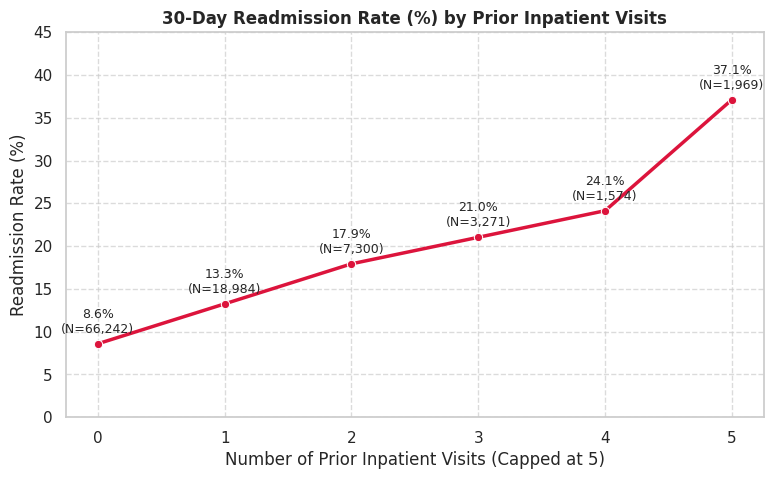

Saved: eda_plots/prior_inpatient_vs_readmission.png


In [24]:
# --- 4. Prior Inpatient Visits vs. Readmission Rate ---
plt.figure(figsize=(9, 5))
# Bin values above 5 into '5+' to maintain robust sample sizes per point
df_feat['prior_inpatient_binned'] = df_feat['number_inpatient'].apply(lambda x: min(x, 5))
inpatient_stats = df_feat.groupby('prior_inpatient_binned')[target].agg(['count', 'mean']).reset_index()
inpatient_stats['mean'] *= 100

sns.lineplot(data=inpatient_stats, x='prior_inpatient_binned', y='mean', marker='o', color='crimson', linewidth=2.5)
plt.title('30-Day Readmission Rate (%) by Prior Inpatient Visits', fontsize=12, fontweight='bold')
plt.xlabel('Number of Prior Inpatient Visits (Capped at 5)')
plt.ylabel('Readmission Rate (%)')
plt.grid(True, linestyle='--', alpha=0.7)

# Annotate the markers with rate and cohort counts
for _, row in inpatient_stats.iterrows():
    plt.annotate(f"{row['mean']:.1f}%\n(N={int(row['count']):,})",
                 (row['prior_inpatient_binned'], row['mean']),
                 textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9)

plt.ylim(0, 45)
fig_path_inpatient = 'eda_plots/prior_inpatient_vs_readmission.png'
plt.savefig(fig_path_inpatient, dpi=300)
plt.show()
print(f"Saved: {fig_path_inpatient}")

Total unique patients: 69,987
Patients with multiple encounters: 16,341 (23.35%)


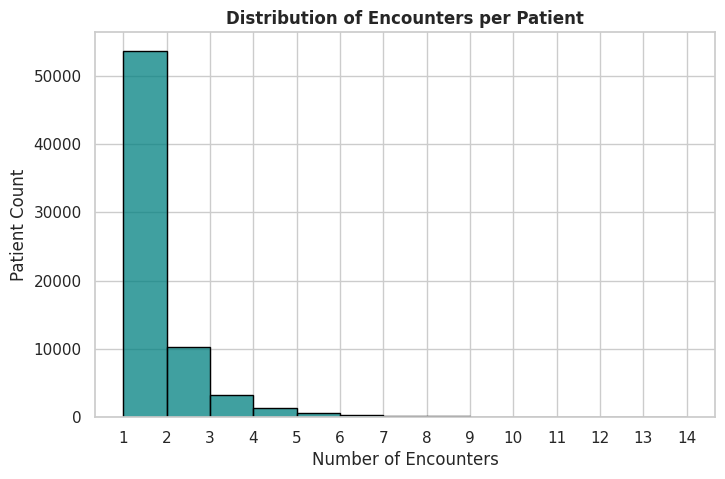

Saved: eda_plots/encounters_per_patient.png


In [25]:
# --- 5. Patients with Multiple Encounters Distribution ---
encounters_per_patient = df_feat['patient_nbr'].value_counts()
multi_encounter_patients_count = (encounters_per_patient > 1).sum()
total_patients = len(encounters_per_patient)

print(f"Total unique patients: {total_patients:,}")
print(f"Patients with multiple encounters: {multi_encounter_patients_count:,} ({multi_encounter_patients_count / total_patients * 100:.2f}%)")

plt.figure(figsize=(8, 5))
sns.histplot(encounters_per_patient, bins=range(1, 15), kde=False, color='teal', edgecolor='black')
plt.title('Distribution of Encounters per Patient', fontsize=12, fontweight='bold')
plt.xlabel('Number of Encounters')
plt.ylabel('Patient Count')
plt.xticks(range(1, 15))

fig_path_encounters = 'eda_plots/encounters_per_patient.png'
plt.savefig(fig_path_encounters, dpi=300)
plt.show()
print(f"Saved: {fig_path_encounters}")

In [26]:
# --- 6. Univariate baseline table for future MIMIC comparison ---
univariate_baseline = []
for col in cat_cols:
    grp = df_feat.groupby(col)[target].agg(['count', 'mean']).reset_index()
    grp.columns = ['Level Value', 'Encounter Count', 'Readmit Rate (30d)']
    grp['Feature'] = col
    univariate_baseline.append(grp[['Feature', 'Level Value', 'Encounter Count', 'Readmit Rate (30d)']])

df_univariate_table = pd.concat(univariate_baseline, ignore_index=True)
df_univariate_table['Readmit Rate (30d)'] = (df_univariate_table['Readmit Rate (30d)'] * 100).round(2).astype(str) + '%'

print("\n--- Univariate Baseline Table (First 20 records shown) ---")
display(df_univariate_table.head(20))
df_univariate_table.to_csv('eda_plots/univariate_baseline_table.csv', index=False)
print("Saved univariate_baseline_table.csv")


--- Univariate Baseline Table (First 20 records shown) ---


,Feature,Level Value,Encounter Count,Readmit Rate (30d)
0,age_band,[0-10),160,1.88%
1,age_band,[10-20),690,5.8%
2,age_band,[20-30),1649,14.31%
3,age_band,[30-40),3764,11.26%
4,age_band,[40-50),9607,10.66%
5,age_band,[50-60),17060,9.77%
6,age_band,[60-70),22058,11.3%
7,age_band,[70-80),25329,12.06%
8,age_band,[80-90),16434,12.57%
9,age_band,[90-100),2589,11.9%


Saved univariate_baseline_table.csv


### Summary of Exploratory Data Analysis (EDA) & Discoveries

All plots have been successfully generated and saved to the `eda_plots/` directory. Below is a detailed breakdown of the key findings from our analysis:

#### 1. Readmission Rates by Categorical Features (`readmission_rates_by_categorical.png`)
* **Age**: The youngest patients `[0-10)` and `[10-20)` exhibit extremely low 30-day readmission rates (1.88% and 5.8% respectively). The peak readmission risk occurs in young adults aged `[20-30)` at **14.31%**, after which rates hover consistently between **10% and 12.5%** across older adult groups.
* **Discharge Disposition**: Patients discharged to rehab facilities exhibit the highest risk (**~27%**), followed by those transferred to other inpatient institutions (~21%) or Skilled Nursing Facilities (SNFs) (~14.66%). Patients discharged directly to home have the lowest readmission rates (**9.3%**).
* **Primary Diagnosis**: Patients admitted with a primary diagnosis of **Diabetes (13.1%)** or **Injury (12.4%)** have significantly higher readmission rates compared to those with Respiratory (10.0%) or Musculoskeletal (9.5%) conditions.
* **A1C & Medication Change**: Patients with no medication changes (`change == "No"`) readmit at a slightly lower rate (**10.84%**) than those experiencing active modifications (**12.02%**).

#### 2. Distributions, Skew, and Outliers (`numeric_distributions.png`)
* **Highly Skewed Features**: `prior_visits_total` exhibits extreme right-skewness (**skew of 5.35**), highlighting a small cohort of extremely high-utilizer patients. Log-transformations or capping are highly justified here before linear or distance-based model fitting.
* **Stable Features**: `num_lab_procedures` (skew of -0.24) and `number_diagnoses` (skew of -0.86) have relatively normal/left-skewed symmetric distributions with fewer extreme outliers.

#### 3. Multicollinearity & Associations (`pearson_correlation.png` & `cramers_v_association.png`)
* **Numerical Associations**: Strongest positive correlations exist between `time_in_hospital` and `num_medications` (**0.46**), as well as `num_procedures` and `num_medications` (**0.38**). This indicates expected clinical coupling (more hospital days or procedures lead to higher medication counts) but no severe multicollinearity that would compromise model stability.
* **Categorical Associations**: Cram'er's V associations are generally weak (all coefficients < 0.15). The strongest link exists between `admission_type_clean` and `diag_1_grouped` (**0.14**), showing that the categorical variables bring independent, non-redundant feature signals to the predictive task.

#### 4. The Strongest Signal: Prior Inpatient Footprint (`prior_inpatient_vs_readmission.png`)
* There is a **linear/monotonic relationship** between prior inpatient hospitalizations and readmission rate.
* Patients with **0 prior inpatient visits** have a **8.6%** readmission rate.
* This rate jumps to **13.3%** with 1 prior visit, **17.9%** with 2 visits, and climbs to **37.1%** for high-utilizer patients with 5 or more prior visits. This confirms that historical acute utilization is indeed the single most powerful univariate signal.

#### 5. Recurrent Patient Footprint (`encounters_per_patient.png`)
* Of the **69,987 unique patients** in our cohort, **16,341 (23.35%)** have multiple hospital encounters recorded.
* The maximum number of visits for a single patient is **40 encounters**. This reinforces the importance of using **GroupKFold cross-validation split on patient IDs** to completely block patient-level data leakage between training and evaluation folds.